# Phase 5c — Fine-tuning a small transformer on CVE descriptions

In 5b the sentence encoder was **frozen**: only a small model on top learned from our labels (transfer learning).
Here the whole encoder (MiniLM-L6, 22M parameters; the 6b winner) is **fine-tuned end-to-end** on the supervised
task, so its internal representation can adapt to CVE language. The risk is overfitting: 22M parameters and only
a few hundred exploited CVEs per training period.

**Protocol (fixed in advance, run by `src/gpu_run.py finetune` on the Apple GPU, dev only):**
* class-weighted BCE; AdamW, weight decay 0.01, dropout 0.1, max sequence length 128, warm-up 10% then linear decay
* per period: epoch search (max **3** epochs) on the training period minus its last 6 months, stopping set = those
  6 months; then **refit on the full period** for the best epoch count (same seed); score the evaluation rows
* grid of **4 settings**: learning rate {1e-5, 2e-5} × {all layers trained, embeddings + lower 3 of 6 layers frozen}
* deviations, for the ~1.5 h GPU budget: negatives in training/stopping sets **subsampled to 25%** (all positives
  kept; one fixed subsample seed, so every setting sees the same CVEs); **2 seeds** for the chosen setting (not 3);
  frozen settings use "eager" attention (the fused MPS attention kernel has no dropout when layers are frozen)
* same selection rule as all Phase 5 models: mean recall@110 per month over WF 2023, WF 2024-H1, val

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "mpl")); os.environ.setdefault("LOKY_MAX_CPU_COUNT", "8")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from metrics import recall_at_k, recall_curve, random_recall_at_k, bootstrap_recall_at_k, ci_table, pr_auc
from description_leak import PHRASES, phrase_flags
from features import load_kev_raw
from tabular_models import build_X, make_hgb, views
import text_models as txm

FIG, TAB, FT = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables", ROOT / "data" / "finetune"
BLUE, ORANGE, AQUA, VIOLET, MAGENTA, GREEN, INK, INK2, GRID, SURF = ("#2a78d6", "#eb6834", "#1baf7a", "#6250d6",
    "#e87ba4", "#008300", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb")
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 10, "font.size": 9.5})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
K_MAIN, K_GEN = 110, 305
PERIODS = ["wf_2023", "wf_2024h1", "val"]
SETTINGS = ["lr1e-5_full", "lr2e-5_full", "lr1e-5_freeze", "lr2e-5_freeze"]
HGB_BEST = dict(encoding="onehot", learning_rate=0.03, max_leaf_nodes=15, min_samples_leaf=100)

dev = pd.read_parquet(ROOT / "data" / "dev.parquet")
y = dev["label"].to_numpy()
pos = pd.Series(np.arange(len(dev)), index=dev["cve_id"])

def ft_scores(setting, seed):
    """{period: scores aligned to that period's evaluation rows (dev order)}"""
    out = {}
    for p, (_, ev) in views(dev).items():
        s = pd.read_parquet(FT / f"{setting}_s{seed}_{p}.parquet").set_index("cve_id")["score"]
        out[p] = s.reindex(dev.loc[ev, "cve_id"]).to_numpy()
        assert not np.isnan(out[p]).any()
    return out

def summarize(scores):
    r = {}
    for p, (_, ev) in views(dev).items():
        part = dev[ev]
        r[f"{p}@{K_MAIN}"] = recall_at_k(part, pd.Series(scores[p], index=part.index), K_MAIN)
        if p == "val": r[f"val@{K_GEN}"] = recall_at_k(part, pd.Series(scores[p], index=part.index), K_GEN)
    pp = [r[f"{p}@{K_MAIN}"] for p in PERIODS]
    r["worst"], r["selection"] = min(pp), float(np.mean(pp))
    return r
print("fine-tuning outputs:", len(list(FT.glob("*.parquet"))), "score files")

fine-tuning outputs: 15 score files


## 1. The grid (seed 0)

In [2]:
rows = []
for st in SETTINGS:
    info = [json.loads((FT / f"{st}_s0_{p}.json").read_text()) for p in PERIODS]
    r = summarize(ft_scores(st, 0))
    rows.append({"setting": st, **{k: round(100 * v, 1) for k, v in r.items()},
                 "best epochs (WF23, WF24H1, val)": str([i["best_epoch"] for i in info]),
                 "GPU minutes": round(sum(i["minutes"] for i in info), 1)})
grid = pd.DataFrame(rows).sort_values("selection", ascending=False).reset_index(drop=True)
display(grid); grid.to_csv(TAB / "05c_finetune_grid.csv", index=False)
CHOSEN = grid.loc[0, "setting"]
print(f"selected setting: {CHOSEN} | grid GPU time: {grid['GPU minutes'].sum():.1f} min")

,setting,val@110,val@305,wf_2023@110,wf_2024h1@110,worst,selection,"best epochs (WF23, WF24H1, val)",GPU minutes
0,lr1e-5_full,26.5,51.5,37.2,46.7,26.5,36.8,"[3, 3, 2]",22.2
1,lr2e-5_freeze,27.9,54.4,35.5,46.7,27.9,36.7,"[3, 2, 2]",14.4
2,lr2e-5_full,36.8,58.8,37.2,35.6,35.6,36.5,"[3, 1, 2]",19.1
3,lr1e-5_freeze,26.5,54.4,19.8,44.4,19.8,30.2,"[3, 3, 3]",16.8


selected setting: lr1e-5_full | grid GPU time: 72.5 min


**Takeaway**: All four fine-tuned settings score **30.2–36.8%** on the selection rule, **below the frozen-encoder text MLP (39.5%)** and text LR (39.2%). The selected setting is **lr 1e-5 with all layers trained (36.8%)**, but the top three are within 0.3 points, which is pure noise. The four settings used **72.5 min** of GPU time; with seed 1 (22.2 min) the total is about **95 min**, close to the 1.5 h budget.

## 2. Overfitting check: training vs stopping-set loss per epoch
Each panel = one period; one colour per setting; solid = training loss, dashed = stopping-set loss (same
class weight). **Overfitting** = the stopping-set loss rises after its minimum while the training loss keeps
falling. (Training loss is averaged over the epoch while the model changes; stopping-set loss is measured at
the end of the epoch, so the curves are not exactly comparable in level, only in direction.)

,period,setting,stop-loss min at epoch,stop-loss rise after min,train loss fell,train-stop gap at epoch 3,overfitting
0,wf_2023,lr1e-5_full,3,0.000,True,-0.002,no
1,wf_2023,lr2e-5_full,3,0.000,True,0.173,no
2,wf_2023,lr1e-5_freeze,3,0.000,True,-0.029,no
3,wf_2023,lr2e-5_freeze,3,0.000,True,0.024,no
4,wf_2024h1,lr1e-5_full,3,0.000,True,0.483,no
5,wf_2024h1,lr2e-5_full,1,0.334,True,1.113,yes
6,wf_2024h1,lr1e-5_freeze,3,0.000,True,0.213,no
7,wf_2024h1,lr2e-5_freeze,2,0.003,True,0.513,yes
8,val,lr1e-5_full,2,0.007,True,0.058,yes
9,val,lr2e-5_full,2,0.008,True,0.281,yes


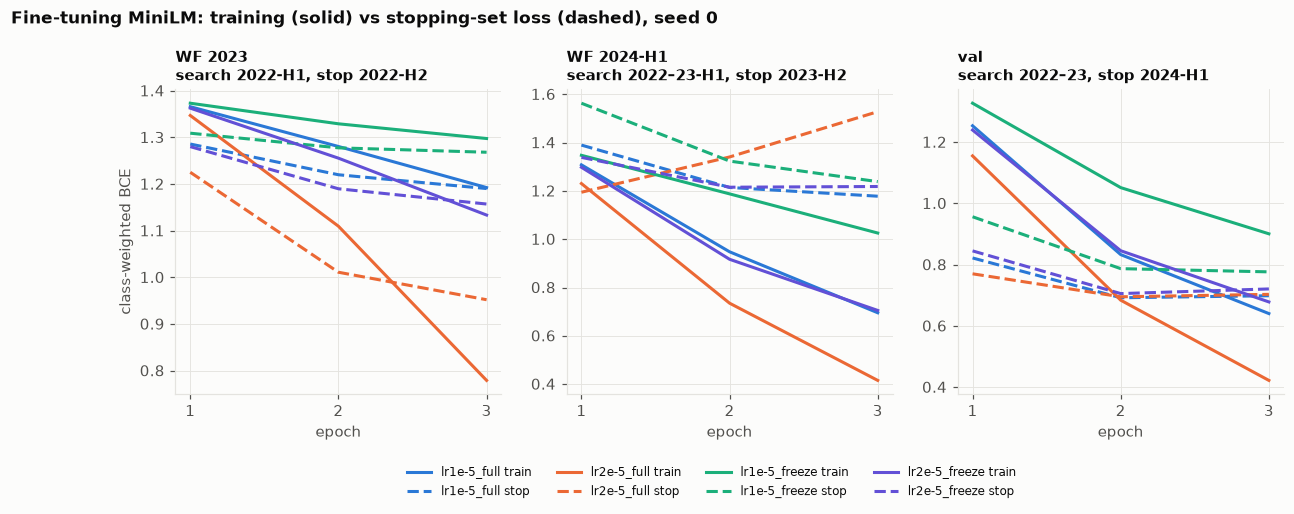

In [3]:
colors = dict(zip(SETTINGS, [BLUE, ORANGE, AQUA, VIOLET]))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
diag = []
titles = {"wf_2023": "WF 2023\nsearch 2022-H1, stop 2022-H2", "wf_2024h1": "WF 2024-H1\nsearch 2022–23-H1, stop 2023-H2",
          "val": "val\nsearch 2022–23, stop 2024-H1"}
for ax, p in zip(axes, PERIODS):
    for st in SETTINGS:
        h = pd.DataFrame(json.loads((FT / f"{st}_s0_{p}.json").read_text())["search_history"])
        ax.plot(h["epoch"], h["train_loss"], color=colors[st], lw=2, label=f"{st} train")
        ax.plot(h["epoch"], h["es_loss"], color=colors[st], lw=2, ls="--", label=f"{st} stop")
        best = int(h["es_loss"].idxmin())
        rises = bool((h["es_loss"].iloc[best + 1:] > h["es_loss"].iloc[best] + 1e-3).any())
        diag.append({"period": p, "setting": st, "stop-loss min at epoch": best + 1,
                     "stop-loss rise after min": round(float(h["es_loss"].iloc[-1] - h["es_loss"].iloc[best]), 3),
                     "train loss fell": bool(h["train_loss"].iloc[-1] < h["train_loss"].iloc[0]),
                     "train-stop gap at epoch 3": round(float(h["es_loss"].iloc[-1] - h["train_loss"].iloc[-1]), 3),
                     "overfitting": "yes" if rises else "no"})
    ax.set_title(titles[p], loc="left"); ax.set_xlabel("epoch"); ax.set_xticks([1, 2, 3])
axes[0].set_ylabel("class-weighted BCE")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.18), fontsize=8)
fig.suptitle("Fine-tuning MiniLM: training (solid) vs stopping-set loss (dashed), seed 0", x=0.01, y=1.08, ha="left", fontweight="bold")
save(fig, "05c_01_finetune_loss_curves")
diag = pd.DataFrame(diag); display(diag); diag.to_csv(TAB / "05c_overfitting_diagnostics.csv", index=False)

**Takeaway**: **Yes, there is overfitting, and it grows with learning rate and training-set size.** The clearest case is **lr 2e-5 with all layers on WF 2024-H1**: the stopping-set loss is lowest after epoch 1 (1.19), then rises to 1.53 by epoch 3 while the training loss falls from 1.23 to 0.42. Mild overfitting (stopping-set loss up 0.003–0.015 after epoch 2) appears on val for three of four settings. **Freezing the lower half helps but does not remove it**: at lr 2e-5 the stopping-set loss on WF 2024-H1 rises only 0.003 instead of 0.33. Combined with the low learning rate, freezing **underfits** instead (lr 1e-5 frozen: still improving at epoch 3, worst score 30.2%, WF 2023 only 19.8%). On the small WF 2023 period (3,190 training CVEs) no setting overfits within 3 epochs. The early-stopping + refit protocol caught every overfitting case (it chose 1–2 epochs exactly where the stopping-set loss turned up).

## 3. The chosen setting over 2 seeds vs the frozen-encoder text models
The 5b reference models are recomputed here on the same three periods so every number is directly comparable.

In [4]:
kev = load_kev_raw(sorted((ROOT / "data" / "raw").glob("kev_*.csv"))[-1])
X_tab = build_X(dev, kev)
E = txm.load_embeddings("minilm", dev)
REF = {}
rule = 100 * phrase_flags(dev["description_day0"], PHRASES).any(axis=1).to_numpy() + dev["cvss_cna_score"].fillna(-1).to_numpy()
REF["phrase, then CVSS (CNA)"] = txm.eval_periods(dev, lambda f, e: rule[e])
REF["gradient boosting (05a)"] = txm.eval_periods(dev, lambda f, e: make_hgb(**HGB_BEST).fit(X_tab[f], y[f]).predict_proba(X_tab[e])[:, 1])
REF["text LR (05b)"] = txm.eval_periods(dev, txm.text_lr_scorer(E, y, 1.0))
mlp_runs = [txm.eval_periods(dev, txm.mlp_scorer(dev, E, y, (64,), 1e-3, s)) for s in range(5)]
REF["text MLP (05b, 5 seeds)"] = {**{k: np.mean([r[k] for r in mlp_runs]) for k in mlp_runs[0] if not k.startswith("_")},
                                  "_scores": {p: np.mean([r["_scores"][p] for r in mlp_runs], axis=0) for p in PERIODS},
                                  "_worst_seed": min(r["selection"] for r in mlp_runs)}
ft_runs = [summarize(ft_scores(CHOSEN, s)) for s in (0, 1)]
ft_ens = {p: np.mean([ft_scores(CHOSEN, s)[p] for s in (0, 1)], axis=0) for p in PERIODS}
REF[f"fine-tuned MiniLM ({CHOSEN}, 2 seeds)"] = {**{k: np.mean([r[k] for r in ft_runs]) for k in ft_runs[0]},
                                                "_scores": ft_ens, "_worst_seed": min(r["selection"] for r in ft_runs)}
seed_tbl = pd.DataFrame([{"seed": s, **{k: round(100 * v, 1) for k, v in r.items()}} for s, r in zip((0, 1), ft_runs)])
print(f"fine-tuned {CHOSEN}, per seed:"); display(seed_tbl)
cmp_ = pd.DataFrame([{"model": m, **{k: round(100 * v, 1) for k, v in r.items() if not k.startswith("_")},
                      "worst seed (selection)": round(100 * r["_worst_seed"], 1) if "_worst_seed" in r else ""} for m, r in REF.items()]).set_index("model")
display(cmp_)
FT_NAME = f"fine-tuned MiniLM ({CHOSEN}, 2 seeds)"
BEATS = REF[FT_NAME]["selection"] > REF["text MLP (05b, 5 seeds)"]["selection"]
print(f"Decision 11b: fine-tuned beats the text MLP on the selection rule? {BEATS} "
      f"({100*REF[FT_NAME]['selection']:.1f} vs {100*REF['text MLP (05b, 5 seeds)']['selection']:.1f})")

fine-tuned lr1e-5_full, per seed:


,seed,val@110,val@305,wf_2023@110,wf_2024h1@110,worst,selection
0,0,26.5,51.5,37.2,46.7,26.5,36.8
1,1,26.5,55.9,33.1,37.8,26.5,32.4


,val@110,val@305,wf_2023@110,wf_2024h1@110,worst,selection,worst seed (selection)
model,,,,,,,
"phrase, then CVSS (CNA)",28.1,42.7,39.3,34.9,28.1,34.1,
gradient boosting (05a),47.1,67.6,39.7,55.6,39.7,47.4,
text LR (05b),23.5,45.6,43.0,51.1,23.5,39.2,
"text MLP (05b, 5 seeds)",30.6,50.3,43.0,44.9,30.6,39.5,38.7
"fine-tuned MiniLM (lr1e-5_full, 2 seeds)",26.5,53.7,35.1,42.2,26.5,34.6,32.4


Decision 11b: fine-tuned beats the text MLP on the selection rule? False (34.6 vs 39.5)


**Takeaway**: Over 2 seeds the chosen setting averages **34.6%** (seed 0: 36.8%, seed 1: **32.4%**), barely above the best rule (34.1%) and **4.9 points below the text MLP (39.5%)**. The 4.4-point gap between two seeds of the *same* setting is larger than the gap between the top three settings, so fine-tuning is also the least stable text model. **Decision 11b: the fine-tuned model does not beat the text MLP, so it does not enter the late fusion.** Likely reasons: only 25% of negatives, at most 3 epochs, and 22M parameters fit to a few hundred positives per period. The frozen encoder plus a small head generalises better with this little labelled data.

## 4. Late fusion and the final-model rule (Decision 11)
Late fusion = average of within-month percentile ranks of gradient boosting and the text model. Decision 11b:
the fine-tuned model replaces the text MLP inside the fusion **only if** it beats the text MLP on the selection
rule. Both fusions are shown for transparency; only the rule decides.

In [5]:
def fuse(a, b):
    out = {}
    for p, (_, ev) in views(dev).items():
        part = dev[ev]
        out[p] = (txm.month_pct_rank(part, a[p]) + txm.month_pct_rank(part, b[p])) / 2
    return out
REF["late fusion: boosting + text MLP"] = {**summarize(fuse(REF["gradient boosting (05a)"]["_scores"], REF["text MLP (05b, 5 seeds)"]["_scores"])),
    "_scores": fuse(REF["gradient boosting (05a)"]["_scores"], REF["text MLP (05b, 5 seeds)"]["_scores"])}
REF["late fusion: boosting + fine-tuned (info only)"] = {**summarize(fuse(REF["gradient boosting (05a)"]["_scores"], ft_ens)),
    "_scores": fuse(REF["gradient boosting (05a)"]["_scores"], ft_ens)}
fusion_text = "late fusion: boosting + fine-tuned (info only)" if BEATS else "late fusion: boosting + text MLP"
if BEATS:
    REF["late fusion: boosting + fine-tuned"] = REF.pop("late fusion: boosting + fine-tuned (info only)"); fusion_text = "late fusion: boosting + fine-tuned"
# Decision 11a: highest selection wins; within 2 points -> better worst period
cand = {m: REF[m] for m in ["gradient boosting (05a)", fusion_text]}
best_sel = max(c["selection"] for c in cand.values())
close = {m: c for m, c in cand.items() if best_sel - c["selection"] <= 0.02}
FINAL = max(close, key=lambda m: (close[m]["worst"], close[m]["selection"]))
for m, c in cand.items():
    print(f"{m:40s} selection {100*c['selection']:.1f} | worst period {100*c['worst']:.1f}")
print(f"-> Decision 11 final model: {FINAL}")

gradient boosting (05a)                  selection 47.4 | worst period 39.7
late fusion: boosting + text MLP         selection 46.7 | worst period 42.6
-> Decision 11 final model: late fusion: boosting + text MLP


**Takeaway**: Applying Decision 11 exactly as written before these results: gradient boosting 47.4% vs late fusion (boosting + text MLP) 46.7%, within 2 points, so the better **worst period** decides → **late fusion is the final model (worst period 42.6% vs 39.7%)**, with gradient boosting as the simpler alternative. For transparency: a fusion with the fine-tuned model *would* score slightly higher (47.2%, worst 44.1%), but the difference is **one exploited CVE on val** (30 vs 29 of 68; identical counts on both walk-forward periods, 56/121 and 23/45, even though the scores differ, correlation 0.85–0.89). Since the pre-registered rule only lets the fine-tuned model in if it beats the text MLP on its own, we do not adopt it: switching now would be choosing on noise after seeing results.

## 5. Validation with bootstrap CIs and recall vs capacity
Neural-net scores on val are seed ensembles (fine-tuned: 2 seeds; text MLP: 5 seeds).

,point@110,lo@110,hi@110,point@305,lo@305,hi@305
method,,,,,,
gradient boosting (05a),47.1,35.5,59.7,67.6,56.5,78.7
late fusion: boosting + fine-tuned (info only),44.1,31.3,55.6,77.9,67.7,87.5
late fusion: boosting + text MLP,42.6,30.2,54.5,64.7,54.3,76.9
"text MLP (05b, 5 seeds)",32.4,20.3,42.9,50.0,38.2,63.0
"phrase, then CVSS (CNA)",28.1,16.9,38.2,42.7,31.2,54.5
"fine-tuned MiniLM (lr1e-5_full, 2 seeds)",25.0,14.7,36.1,57.4,44.0,68.2


fine-tuned minus text MLP (05b, 5 seeds) @110: -6.5 [-15.9, +2.9], P(better) = 6%
fine-tuned minus phrase, then CVSS (CNA) @110: -2.8 [-19.3, +15.2], P(better) = 33%


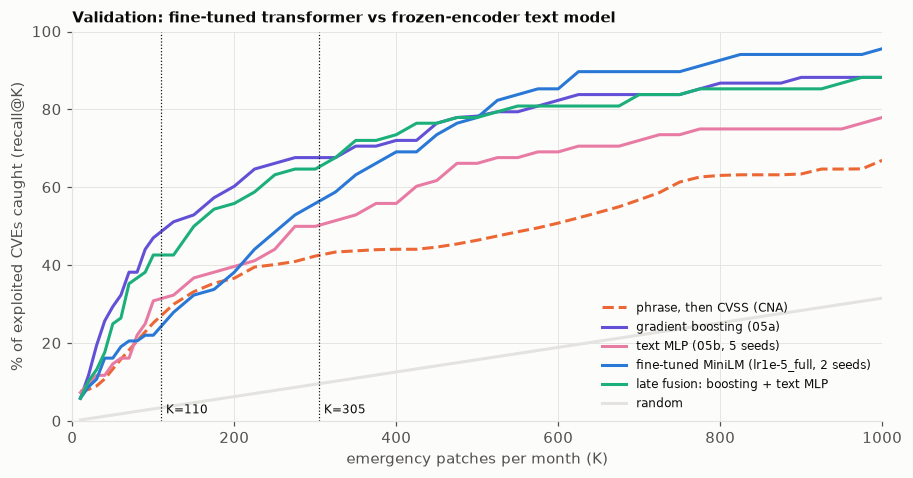

In [6]:
val_mask = dev["split"].eq("val").to_numpy(); val = dev[val_mask].reset_index(drop=True)
cands = ["phrase, then CVSS (CNA)", "gradient boosting (05a)", "text MLP (05b, 5 seeds)", FT_NAME,
         "late fusion: boosting + text MLP", [k for k in REF if k.startswith("late fusion: boosting + fine-tuned")][0]]
SC = {c: pd.Series(REF[c]["_scores"]["val"]) for c in cands}
point = {(m, k): recall_at_k(val, s, k) for m, s in SC.items() for k in (K_MAIN, K_GEN)}
boot = bootstrap_recall_at_k(val, SC, [K_MAIN, K_GEN], n_boot=2000, seed=0)
ci = ci_table(boot, point)
tbl = ci.mul(100).round(1).reset_index().pivot(index="method", columns="k"); tbl.columns = [f"{a}@{b}" for a, b in tbl.columns]
display(tbl[[f"{c}@{k}" for k in (K_MAIN, K_GEN) for c in ("point", "lo", "hi")]].sort_values(f"point@{K_MAIN}", ascending=False))
piv = boot.pivot_table(index=["rep", "k"], columns="method", values="recall")
for base in ["text MLP (05b, 5 seeds)", "phrase, then CVSS (CNA)"]:
    d = 100 * (piv[FT_NAME] - piv[base]).xs(K_MAIN, level="k")
    print(f"fine-tuned minus {base} @110: {d.mean():+.1f} [{d.quantile(.025):+.1f}, {d.quantile(.975):+.1f}], P(better) = {(d > 0).mean():.0%}")
ci.to_csv(TAB / "05c_val_ci.csv")

ks = np.unique(np.r_[np.arange(10, 100, 10), np.arange(100, 1001, 25)])
style = {"phrase, then CVSS (CNA)": (ORANGE, "--"), "gradient boosting (05a)": (VIOLET, "-"), "text MLP (05b, 5 seeds)": (MAGENTA, "-"),
         FT_NAME: (BLUE, "-"), "late fusion: boosting + text MLP": (AQUA, "-")}
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for m in cands:
    if m not in style: continue
    c, ls = style[m]; ax.plot(ks, 100 * recall_curve(val, SC[m], ks), color=c, ls=ls, lw=2, label=m)
ax.plot(ks, [100 * random_recall_at_k(val, k) for k in ks], color=GRID, lw=2, label="random")
for k in (K_MAIN, K_GEN):
    ax.axvline(k, color=INK, lw=0.8, ls=":"); ax.annotate(f"K={k}", (k, 2), fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.set_xlabel("emergency patches per month (K)"); ax.set_ylabel("% of exploited CVEs caught (recall@K)")
ax.set_ylim(0, 100); ax.set_xlim(0, 1000); ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title("Validation: fine-tuned transformer vs frozen-encoder text model", loc="left")
save(fig, "05c_02_val_recall_vs_k")

**Takeaway**: On val at K = 110 the fine-tuned model (2-seed ensemble) catches **25.0%** [15–36] of exploited CVEs: **−6.5 points vs the text MLP** (P(better) = 6%) and −2.8 vs the best rule (P = 33%). At K = 305 it does better (57.4% vs 50.0% for the text MLP), the same pattern as in 5b: text helps more once the obvious candidates are patched. Its recall-vs-K curve stays below the text MLP at small capacity, crosses it at ~200/month, and is the highest curve of all from ~600/month (≈ 90% recall), but those capacities are far above our K.

## 6. Comparison table — all Phase 5 methods (three periods + validation CIs)

In [7]:
prev = pd.read_csv(TAB / "05b_comparison.csv")
def fmt(m, k):
    if (m, k) not in ci.index: return ""
    r = ci.loc[(m, k)]; return f"{100*r['point']:.1f} [{100*r['lo']:.0f}–{100*r['hi']:.0f}]"
rows = []
for m in ["phrase, then CVSS (CNA)", "gradient boosting (05a)", "text LR (05b)", "text MLP (05b, 5 seeds)", FT_NAME,
          "late fusion: boosting + text MLP", [k for k in REF if k.startswith("late fusion: boosting + fine-tuned")][0]]:
    r = REF[m]
    rows.append({"method": m, "selection (3-period mean)": round(100 * r["selection"], 1), "WF 2023": round(100 * r["wf_2023@110"], 1),
                 "WF 2024-H1": round(100 * r["wf_2024h1@110"], 1), "worst period": round(100 * r["worst"], 1),
                 "worst seed": round(100 * r["_worst_seed"], 1) if "_worst_seed" in r else "",
                 "val recall@110 [CI]": fmt(m, K_MAIN) or f"{100*r['val@110']:.1f}", "val recall@305 [CI]": fmt(m, K_GEN) or f"{100*r['val@305']:.1f}",
                 "final model (Decision 11)": "<- headline" if m == FINAL else ("simpler alternative" if m == "gradient boosting (05a)" else "")})
final = pd.DataFrame(rows).set_index("method").sort_values("selection (3-period mean)", ascending=False)
display(final); final.to_csv(TAB / "05c_comparison.csv")
print("other 05b models (unchanged): (a) tabular+text MLP 44.8, (b) boosting + OOF text score 45.3 - see 05b")

,selection (3-period mean),WF 2023,WF 2024-H1,worst period,worst seed,val recall@110 [CI],val recall@305 [CI],final model (Decision 11)
method,,,,,,,,
gradient boosting (05a),47.4,39.7,55.6,39.7,,47.1 [36–60],67.6 [57–79],simpler alternative
late fusion: boosting + fine-tuned (info only),47.2,46.3,51.1,44.1,,44.1 [31–56],77.9 [68–88],
late fusion: boosting + text MLP,46.7,46.3,51.1,42.6,,42.6 [30–55],64.7 [54–77],<- headline
"text MLP (05b, 5 seeds)",39.5,43.0,44.9,30.6,38.7,32.4 [20–43],50.0 [38–63],
text LR (05b),39.2,43.0,51.1,23.5,,23.5,45.6,
"fine-tuned MiniLM (lr1e-5_full, 2 seeds)",34.6,35.1,42.2,26.5,32.4,25.0 [15–36],57.4 [44–68],
"phrase, then CVSS (CNA)",34.1,39.3,34.9,28.1,,28.1 [17–38],42.7 [31–55],


other 05b models (unchanged): (a) tabular+text MLP 44.8, (b) boosting + OOF text score 45.3 - see 05b


**Takeaway**: Fine-tuning the transformer **did not pay off**: 34.6% on the selection rule, below the frozen-encoder text MLP (39.5%) and only just above the best day-0 rule (34.1%), with large seed-to-seed swings and clear overfitting at the higher learning rate. **The final model under Decision 11 stays late fusion of gradient boosting and the text MLP** (selection 46.7%, best worst period 42.6%), with gradient boosting alone (47.4%) as the simpler alternative. Both will be scored once on test in Phase 6; only late fusion is the headline. Optional next rungs (domain-adaptive MLM pretraining) are unlikely to change this with our label count, and are not planned unless you want them.